# Historic Data Comparison

Data is likely to change over time. In this notebook, we will investigate whether the records provided of the Berlin State Library's OAI-PMH endpoint has changed over the last years.


In [1]:
import gzip
import json
import math
import os
import pickle
import sys
import urllib
from datetime import datetime  # for time measurement
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.colors as pc
import plotly.graph_objects as go
import requests
from plotly.subplots import make_subplots

# try to load cybertqdm if it is available
try:
    from cybertqdm import cybertqdm as tqdm

    print("Using cybertqdm to display progress on external e-ink display.")
except ImportError:
    from tqdm import tqdm

# create the PPN lookup dicts on every run (pretty slow), when 'False' the script will look for
# a pickled version. MUST be 'True' on first run
overrideLookupDicts = False

lookupPickleFile = "./picklez/hist_lookup.picklez"

globalStartTime = datetime.now()

In [2]:
# ANSI-based styling
# Standard foreground colors (30–37)


BLACK = "\033[30m"
RED = "\033[31m"
GREEN = "\033[32m"  # baseline
YELLOW = "\033[33m"
BLUE = "\033[34m"
MAGENTA = "\033[35m"
CYAN = "\033[36m"
WHITE = "\033[37m"

# Bright variants (90–97)
BRIGHT_GREEN = "\033[92m"
BRIGHT_RED = "\033[91m"

# Styles
BOLD = "\033[1m"
DIM = "\033[2m"
UNDERLINE = "\033[4m"
RESET = "\033[0m"

# color scale for plotting
COLOR_SCALE = "dense"


# utility functions
# print a line with the current timestamp
def printLog(text):
    now = str(datetime.now())
    print("[" + now + "]\t" + text)
    # forces to output the result of the print command immediately, see: http://stackoverflow.com/questions/230751/how-to-flush-output-of-python-print
    sys.stdout.flush()


# load a file from an URL and save it to a folder
def saveFileFromURL(file_url, output_dir):
    # get the path part of the URL
    path = urllib.parse.urlparse(file_url).path
    # remove the 8bit-inferno.de-specific path part
    file_part = path.replace("/_persistent/", "")

    printLog(f"Downloading {file_url} to '{output_dir}/{file_part}'")

    # send a GET request to the URL
    response = requests.get(file_url)
    # check if the request was successful
    if response.status_code == 200:
        # Open a local file in binary write mode
        with open(output_dir + "/" + file_part, "wb") as file:
            # Write the content of the response to the file
            file.write(response.content)
        printLog("Finished download.")
        return True
    else:
        printLog(
            f"Failed to download file with HTTP status code: {response.status_code}"
        )
        return False


# serialize an object as a gzipped pickle file
def pickleCompress(fileName, pickledObject):
    printLog("Pickling to '%s'" % fileName)
    f = gzip.open(fileName, "wb")
    pickle.dump(pickledObject, f)
    f.close()
    printLog("Pickling done.")


# load a gzipped pickle file from disk
def pickleDecompress(fileName):
    # restore the object
    printLog("Depickling from '%s'" % fileName)
    f = gzip.open(fileName, "rb")
    pickledObject = pickle.load(f)
    f.close()
    printLog("Depickling done.")
    return pickledObject

## Get The Current Dataset

All datasets needed to run this notebook can be directly download from the web if `loadMissingData` is `True`.

If you want to use your own datasets, you must adjust the paths in the cells below.


In [3]:
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# If 'loadMissingData' is set to True, sample files will be downloaded automatically
# This is a RECOMMENDED SETTING as it will take care of a some extra work for you
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
loadMissingData = True


recordDatabaseFile = "./save_120k_dc_all_DEMO_2026.pickle"
recordDatabaseFileLarge = "./save_246k_dc_all_DEMO.pickle"

# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
#
# Directory used for reports etc.
#
# * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
reportDir = "./reports/"

# create necessary directories
if not os.path.exists(reportDir):
    os.makedirs(reportDir)

In [4]:
if loadMissingData:
    if not os.path.isfile(recordDatabaseFile):
        saveFileFromURL(
            "https://8bit-inferno.de/_persistent/save_120k_dc_all_DEMO_2026.pickle",
            ".",
        )

# load the records
# uncomment the next 3 lines if you are continuing the execution of this notebook at a later point in time
# printLog("Loading pickled records...")
savedRecords = pickle.load(open(recordDatabaseFile, "rb"))
# printLog("Finished loading pickled records.")

availableKeys = dict()

# check for all keys present in the previously downloaded dataset
for i, r in enumerate(savedRecords):
    for k in r.keys():
        if not k in availableKeys:
            availableKeys[k] = 1
        else:
            availableKeys[k] = availableKeys[k] + 1

print(availableKeys)

# create a dictionary for the records
values = dict()
# take the keys as they have found within the downloaded OAI records
keys = availableKeys.keys()
# for every metadata field, create an empty array as the content of the dictionary filed under the key 'k'
for k in keys:
    values[k] = []
# in addition, store the PPN (the SBB's unique identifier for digitized content)
# values["PPN"]=[]

# iterate over all saved records
# note: in 2026 this creation of a dataframe has become pretty verbose, for a more straightforward approach see the cells below
# however, we keep this ancient code here as it shows detailed how it was once done, even when Python 2 was still a thing
for record in savedRecords:
    # we cannot iterate over the keys of record.metadata directly because not all records cotain the same fields,...
    for k in keys:
        # thus we check if the metadata field 'k' has been created above
        if k in values:
            # append the metadata fields to the dictionary created above
            # if the metadata field 'k' is not available input "None" instead
            # values[k].append(record.get(k,["None"])[0].encode('ISO-8859-1'))
            if k in record:
                value = record.get(k)[0]
                if value:
                    if value.isdigit():
                        value = int(value)
                    else:
                        # p27 value=value.encode('ISO-8859-1')
                        # value=value.encode('ISO-8859-1').decode("utf-8", "backslashreplace")
                        value = value
                    values[k].append(value)
                else:
                    values[k].append(np.nan)
            else:
                values[k].append(np.nan)
# create a data frame from the
# p27 df=pd.DataFrame(pd.to_numeric(values,errors='coerce'))
df = pd.DataFrame(values)
# df['date']=pd.to_numeric(df['date'],errors='ignore',downcast='integer')
# df=pd.DataFrame(values)
# df=df.convert_objects(convert_dates=False, convert_numeric=True, convert_timedeltas=False, copy=True)
df.shape

{'title': 120000, 'creator': 79390, 'subject': 119694, 'publisher': 39511, 'type': 120000, 'format': 120000, 'identifier': 120000, 'language': 73739, 'date': 117969, 'coverage': 100947, 'rights': 117045, 'PPN': 120000}


(120000, 12)

First, we can inspect the (downloaded) reference dataset `df`.


In [5]:
df.head()

,title,creator,subject,publisher,type,format,identifier,language,date,coverage,rights,PPN
0,"Collegium Ethicum, In Quo De Summo Hominis Bon...","Liebenthal, Christianus",Historische Drucke,Hampelius,monograph,application/mets+xml,PPN1000000974,lat,1620,Giessae Hessorum,Public Domain Mark 1.0,PPN1000000974
1,"Augustini Niphi, Philosophi Suessani De Auguri...","Niphus, Augustinus",Historische Drucke,Egenolphus,monograph,application/mets+xml,PPN100000127X,lat,1614,Marpurgi,Public Domain Mark 1.0,PPN100000127X
2,Concerto pour la Flûte avec Accompagnement de ...,"Danzi, Franz",Musiknoten,Breitkopf & Härtel,monograph,application/mets+xml,PPN1000006808,NaN,1806,Leipsic,CC BY-NC-SA 4.0 International,PPN1000006808
3,Schuldige Condolentz-Zeilen Womit seinem Gelie...,"Koltemann, Otto Benedict",Historische Drucke,Königliche privil. Buchdruckerey,monograph,application/mets+xml,PPN1000056597,ger,1719,Glückstadt,Public Domain Mark 1.0,PPN1000056597
4,Johann Friedrich Böttchers der Arzney und Wund...,"Böttcher, Johann Friedrich",Historische Drucke,Oehmigke,monograph,application/mets+xml,PPN1000059669,ger,1796,Berlin,Public Domain Mark 1.0,PPN1000059669


## Get Historic Datasets

In the next cell, we will setup all historic dataset that we will compare to the reference dataset `df`.
All historical datasets will be downloaded automatically.


In [6]:
# do not change the next list! right now datasets are only available for the years 2019, 2021 and 2022
availableYears = [
    2019,
    2021,
    2022,
]

# indicates whether a sample file could be found (important for later comparisons)
oldPickleAvailable = False

df_per_year2 = dict()
uniquePPNs_over_years = dict()  # holds all PPNs seen in each year

for year in availableYears:
    oldPickle = f"save_120k_dc_all_{year}_DEMO.pickle"
    if not os.path.isfile(oldPickle):
        printLog("The historical sample file could not be found.")
        # check if sample data is available and load it if automatic downloads are set by the user
        if loadMissingData:
            oldPickleAvailable = saveFileFromURL(
                f"https://8bit-inferno.de/_persistent/save_120k_dc_all_{year}_DEMO.pickle",
                ".",
            )
            oldPickle = f"save_120k_dc_all_{year}_DEMO.pickle"

    if os.path.isfile(oldPickle) or oldPickleAvailable:
        oldPickleAvailable = True
        # uncomment this line if you are continuing the execution of this notebook at a later point in time
        savedRecords = pickle.load(open(oldPickle, "rb"))
        printLog(f"Finished loading pickled records for year {year}.")

        # as the values of the dict are lists, we have to make sure to the first element of each list to create a proper dataframe
        r = [
            {key: values[0] for key, values in record.items()}
            for record in savedRecords
        ]
        df_per_year2[year] = pd.DataFrame(r)
        uniquePPNs = set(df_per_year2[year]["PPN"])
        uniquePPNs_over_years[year] = uniquePPNs
        printLog(
            f"Unique PPNs: {YELLOW}{len(uniquePPNs):,}{RESET} [{len(uniquePPNs) / len(df_per_year2[year]):.3%}]"
        )
        df_merge = df.copy()
        intersect = df_merge.merge(df_per_year2[year], on="PPN")
        printLog(
            f"Intersection with current records: {YELLOW}{len(intersect):,}{RESET} [{len(intersect) / len(df_merge):.3%}]"
        )

uniquePPNs = set(df["PPN"])
print("")
printLog("Current records:")
printLog(
    f"Unique PPNs: {YELLOW}{len(uniquePPNs):,}{RESET} [{len(uniquePPNs) / len(df):.3%}]"
)

[2026-11-13 09:06:00.912245]	Finished loading pickled records for year 2019.
[2026-11-13 09:06:01.140646]	Unique PPNs: 104,417 [87.014%]
[2026-11-13 09:06:01.229275]	Intersection with current records: 17,069 [14.224%]
[2026-11-13 09:06:01.593172]	Finished loading pickled records for year 2021.
[2026-11-13 09:06:02.151654]	Unique PPNs: 108,248 [90.207%]
[2026-11-13 09:06:02.239104]	Intersection with current records: 37,850 [31.542%]
[2026-11-13 09:06:02.632101]	Finished loading pickled records for year 2022.
[2026-11-13 09:06:03.089346]	Unique PPNs: 119,997 [99.997%]
[2026-11-13 09:06:03.232857]	Intersection with current records: 79,649 [66.374%]

[2026-11-13 09:06:03.263174]	Current records:
[2026-11-13 09:06:03.263473]	Unique PPNs: 119,988 [99.990%]


As shown above, we can see that our datasets contain duplicates because the PPNs are not unique.

Next, we will download a dataset `df_large` containing all available records (> 246k records) retrieved on November, 1st 2026.


In [7]:
if loadMissingData:
    if not os.path.isfile(recordDatabaseFileLarge):
        saveFileFromURL(
            "https://8bit-inferno.de/_persistent/save_246k_dc_all_DEMO.pickle",
            ".",
        )
savedRecords = pickle.load(open(recordDatabaseFileLarge, "rb"))
printLog(
    f"Finished loading pickled records (large dataset) containing {len(savedRecords):,} records."
)

# as the values of the dict are lists, we have to make sure to the first element of each list to create a proper dataframe
r = [{key: values[0] for key, values in record.items()} for record in savedRecords]
df_large = pd.DataFrame(r)
df_large_set = set(df_large["PPN"])
df_set = set(df["PPN"])

[2026-11-13 09:06:03.918089]	Finished loading pickled records (large dataset) containing 246,522 records.


In the next cell, we check wheter a dataset is a subset of the reference dataset or the complete one.

If no records (indentfied by a PPN) have been dropped, all historic datasets should be a subset of – at least – `df_large`. To remove duplicates, all data is converted to sets.


In [8]:
diff_set_per_year = dict()
intersection_set_per_year = dict()


# returns a red-colored string if bool_value is false
def get_pretty_str(bool_val):
    return "True" if bool_val else f"{RED}False{RESET}"


for year in df_per_year2:
    df_year_set = set(df_per_year2[year]["PPN"])
    diff_set_per_year[year] = df_year_set - df_large_set
    intersection_set_per_year[year] = df_large_set.intersection(df_year_set)
    print(f"{year} [df; unique len.: {len(df_set):,}]")
    print(
        f"\tis subset of 120k reference dataset : {get_pretty_str(df_year_set.issubset(df_set))};\n\tIntersection: {len(df_year_set.intersection(df_set)):,} elements."
    )
    print(f"{year} [df_large; unique len.: {len(df_large_set):,}]")
    print(
        f"\twith {len(df_year_set):,} elements is subset of full reference dataset: {get_pretty_str(df_year_set.issubset(df_large_set))};\n\tIntersection: {len(intersection_set_per_year[year]):,} elements;\n\tDifference: {len(diff_set_per_year[year]):,} elements."
    )

2019 [df; unique len.: 119,988]
	is subset of 120k reference dataset : False;
	Intersection: 13,251 elements.
2019 [df_large; unique len.: 246,504]
	with 104,417 elements is subset of full reference dataset: False;
	Intersection: 104,361 elements;
	Difference: 56 elements.
2021 [df; unique len.: 119,988]
	is subset of 120k reference dataset : False;
	Intersection: 31,642 elements.
2021 [df_large; unique len.: 246,504]
	with 108,248 elements is subset of full reference dataset: False;
	Intersection: 108,203 elements;
	Difference: 45 elements.
2022 [df; unique len.: 119,988]
	is subset of 120k reference dataset : False;
	Intersection: 79,637 elements.
2022 [df_large; unique len.: 246,504]
	with 119,997 elements is subset of full reference dataset: False;
	Intersection: 119,966 elements;
	Difference: 31 elements.


In [9]:
common = (
    set(df["PPN"])
    & set(df_per_year2[2022]["PPN"])
    & set(df_per_year2[2021]["PPN"])
    & set(df_per_year2[2019]["PPN"])
)
printLog(
    f"{YELLOW}{len(common):,}{RESET} [{len(common) / len(df):.3%}] common PPNs across all years; incl. duplicates."
)

result = df[df["PPN"].isin(common)]  # will include duplicates
result.describe()

[2026-11-13 09:06:05.434869]	9,710 [8.092%] common PPNs across all years; incl. duplicates.


,title,creator,subject,publisher,type,format,identifier,language,date,coverage,rights,PPN
count,9712,6900,9707,4384,9713,9713,9713,6653,8941,7737,8022,9713
unique,8963,3552,29,2370,8,1,9710,51,565,1104,5,9710
top,Tibetische Urkunde,"Weber, Gottfried",Historische Drucke,Decker,monograph,application/mets+xml,PPN3306131008,ger,1800,Leipzig,Public Domain Mark 1.0,PPN3306131008
freq,156,194,4776,69,5805,9713,2,2318,347,418,4742,2


In [10]:
# large dataset
common = (
    set(df_large["PPN"])
    & set(df_per_year2[2022]["PPN"])
    & set(df_per_year2[2021]["PPN"])
    & set(df_per_year2[2019]["PPN"])
)
printLog(
    f"{YELLOW}{len(common):,}{RESET} [{len(common) / len(df_large):.3%}] common PPNs across all years; incl. duplicates."
)

result = df_large[df_large["PPN"].isin(common)]  # will include duplicates
result.describe()

[2026-11-13 09:06:05.663777]	29,462 [11.951%] common PPNs across all years; incl. duplicates.


,title,creator,subject,publisher,type,format,identifier,language,date,coverage,rights,PPN
count,29464,20826,29458,19439,29465,29465,29465,24285,28105,25720,25912,29465
unique,27663,11691,34,6441,8,1,29462,82,802,2486,5,29462
top,Tibetische Urkunde,"Schumann, Clara",Historische Drucke,Decker,monograph,application/mets+xml,PPN3306131008,ger,1915,Berlin,Public Domain Mark 1.0,PPN3306131008
freq,156,231,18077,311,20705,29465,2,14162,808,2719,21917,2


In [11]:
all_ppn = set()
df_per_year2["2026"] = df  # add the latest data manually
df_per_year2["2026_246k"] = df_large  # add the latest data manually

# create a union set of all PPNs
for year in df_per_year2:
    df_year_set = set(df_per_year2[year]["PPN"])
    all_ppn |= df_year_set  # union

ppn_in_years = dict()
for year in df_per_year2:
    df_year_set = set(df_per_year2[year]["PPN"])
    for ppn in df_year_set:
        if not ppn in ppn_in_years:
            ppn_in_years[ppn] = []
        ppn_in_years[ppn].append(year)

observation_count = dict()
for ppn in ppn_in_years:
    observations = len(ppn_in_years[ppn])
    if observations not in observation_count:
        observation_count[observations] = 0
    observation_count[observations] += 1

## Visualizations of the Dataset Development

Next, we create a plot to shown over how many years a PPN could be observed.


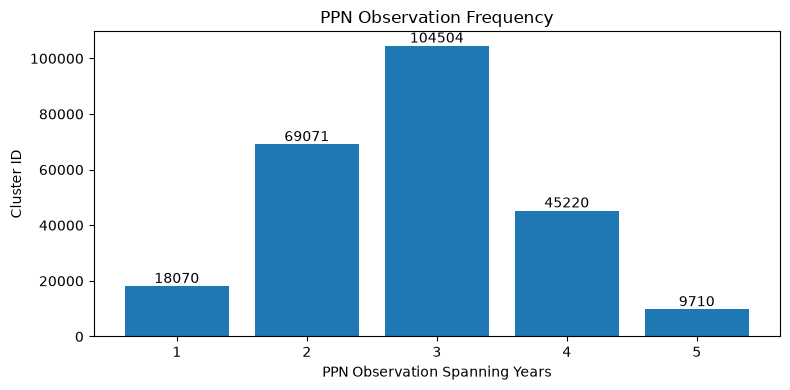

In [12]:
values = observation_count.values()
labels = observation_count.keys()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(
    labels,
    values,
)
ax.set_xlabel("PPN Observation Spanning Years")
ax.set_ylabel("Cluster ID")
ax.set_title("PPN Observation Frequency")
ax.bar_label(ax.containers[0])  # count on top of each bar
plt.tight_layout()
plt.show()

Because the plot shown is not intuitevly comprehensible, we use a Sankey diagram that will display when a PPN could be observed for the first time and when it disappeared.

As this requires a lot of expensive lookup operations, we create a lookup dict that can be re-used in future runs. Please note that the initial creation will take several minutes.


In [13]:
sankey_labels = list(all_ppn | set(["2019", "2021", "2022", "2026", "2026_246k"]))
sankey_source = []
sankey_target = []
sankey_values = []

# the creation of lookup dicts is only necessary if the cells below should be run repeatedly
# if so, you can uncomment the remaining lines of this cell on a re-run
# ATTENTION: make sure to keep the lines active on your first run as the following cells depend on them for faster lookups
index4ppn = dict()  # index lookup dict for PPNs
index4year = dict()  # index lookup dict for years

if overrideLookupDicts or not os.path.exists(lookupPickleFile):
    printLog(f"Creating lookup dicts. This will take a while...")
    for ppn in tqdm(all_ppn):
        index4ppn[ppn] = sankey_labels.index(ppn)

    for year in ["2019", "2021", "2022", "2026", "2026_246k"]:
        index4year[year] = sankey_labels.index(year)

    pickleCompress(lookupPickleFile, (index4ppn, index4year, sankey_labels))
else:
    r = pickleDecompress(lookupPickleFile)
    index4ppn = r[0]
    index4year = r[1]
    sankey_labels = r[2]

[2026-11-13 09:06:06.637564]	Depickling from './picklez/hist_lookup.picklez'
[2026-11-13 09:06:06.680852]	Depickling done.


In the next cell, a Sankey diagram is drawn. In order to keep it readible, we will limit the plotted records to `display_limit` elements.


In [14]:
# debug
# get PPNs that are not in the full dataset
# for ppn in tqdm(ppn_in_years.keys(), desc="Preparing Sankey data"):
#     observations = ppn_in_years[ppn]
#     occurences_weight = len(observations)

#     if "2026_246k" not in observations:
#         print(f"PPN: {ppn}")

# df_large[df_large["PPN"] == "PPN71823362X"]

In [15]:
# debug
picked_explained = {
    "PPN676483054": "[2019]",
    "PPN832954292": "[2019, 2021, '2026_246k']",
    "PPN1046035355": "[2019, 2021, 2022, '2026', '2026_246k']",
    "PPN767019008": "[2019, '2026_246k']",
    "PPN771806124": "[2019, 2021, '2026_246k']",
    "PPN71823362X": "[2019, 2021, 2022]",  # not in full dataset (ends 2022)
}
picked_list = picked_explained.keys()
debug_ppns = picked_list
# debug_ppns = list(ppn_in_years.keys())[10:20]
sankey_source = []
sankey_target = []
sankey_values = []
sankey_custom_data = []

years = ["<2019", "2019", "2021", "2022", "2026", "2026_246k"]

# the start index of the n'th PPN
start_index_nTh_ppn = []
# the index +1 of the n'th PPN to be used in a range selection
index_after_nTh_ppn = []

for ppn in debug_ppns:
    observations = ppn_in_years[ppn]
    occurences_weight = len(observations)
    print(f"{YELLOW}PPN: {ppn}{RESET}")
    print(f"observations: {observations}")
    print(f"occurences_weight: {occurences_weight}")

    start_index_nTh_ppn.append(len(sankey_target))
    print(f"Start index: {len(sankey_target)}")
    for i, year in enumerate(observations):

        print(f"It. {i}")
        if i == 0:
            print(f"\tsankey_source: {years.index("<2019")}")
            print(f"\tsankey_target: {years.index(str(year))}")
            sankey_source.append(years.index("<2019"))
            sankey_target.append(years.index(str(year)))
            if len(observations) > 1:
                print(f"\tsankey_source: {years.index("<2019")}")
                print(f"\tsankey_target: {years.index(str(observations[i + 1]))}")
                sankey_source.append(years.index(str(year)))
                sankey_target.append(years.index(str(observations[i + 1])))
                # sankey_custom_data.append(ppn)

            sankey_custom_data.append(f"{ppn} @ {occurences_weight}")
        else:
            if i < len(observations) - 1:
                print(f"\tsankey_source: {years.index(str(year))}")
                src = years.index(str(year))
                print(f"\tsankey_target: {years.index(str(observations[i + 1]))}")
                target = years.index(str(observations[i + 1]))
                # else:
                #     print(f"\tsankey_target: {years.index(str(year))}")
                #     target = years.index(str(year))
                sankey_source.append(src)
                sankey_target.append(target)
            sankey_custom_data.append(f"{ppn} @ {occurences_weight}")

        sankey_values.append(occurences_weight)
        index_after_nTh_ppn.append(len(sankey_target) + 1)
        print(f"End index +1: {len(sankey_target)+1}")

print("\n" + "--" * 10)
print(sankey_source)
print(sankey_target)
print(f"Length of custom data: {len(sankey_custom_data)}")
print(f"Custom data: {sankey_custom_data}")

PPN: PPN676483054
observations: [2019]
occurences_weight: 1
Start index: 0
It. 0
	sankey_source: 0
	sankey_target: 1
End index +1: 2
PPN: PPN832954292
observations: [2019, 2021, '2026_246k']
occurences_weight: 3
Start index: 1
It. 0
	sankey_source: 0
	sankey_target: 1
	sankey_source: 0
	sankey_target: 2
End index +1: 4
It. 1
	sankey_source: 2
	sankey_target: 5
End index +1: 5
It. 2
End index +1: 5
PPN: PPN1046035355
observations: [2019, 2021, 2022, '2026', '2026_246k']
occurences_weight: 5
Start index: 4
It. 0
	sankey_source: 0
	sankey_target: 1
	sankey_source: 0
	sankey_target: 2
End index +1: 7
It. 1
	sankey_source: 2
	sankey_target: 3
End index +1: 8
It. 2
	sankey_source: 3
	sankey_target: 4
End index +1: 9
It. 3
	sankey_source: 4
	sankey_target: 5
End index +1: 10
It. 4
End index +1: 10
PPN: PPN767019008
observations: [2019, '2026_246k']
occurences_weight: 2
Start index: 9
It. 0
	sankey_source: 0
	sankey_target: 1
	sankey_source: 0
	sankey_target: 5
End index +1: 12
It. 1
End index

In [16]:
SELECTED_PPN_COUNT = 4  # the number of PPNs selected for display
display_limit = index_after_nTh_ppn[
    SELECTED_PPN_COUNT
]  # index sets how many PPNs will be selected
# if you want to display all available PPNs uncomment the following two lines
# display_limit = len(sankey_custom_data)
# SELECTED_PPN_COUNT=len(debug_ppns)

# debug plot
for ppn in list(picked_explained.keys())[:SELECTED_PPN_COUNT]:
    print(f"PPN: {ppn}\t{picked_explained[ppn]}")


# normalise values to 0..1 and sample a colorscale
vals = sankey_values[:display_limit]
vmin, vmax = min(vals), max(vals)
norm = [(v - vmin) / (vmax - vmin) if vmax > vmin else 0.5 for v in vals]
link_colors = pc.sample_colorscale(COLOR_SCALE, norm)  # -> ["rgb(r, g, b)", ...]
# optional: make links semi-transparent so overlaps stay readable
link_colors = [c.replace("rgb", "rgba").replace(")", ", 0.6)") for c in link_colors]

# increase width of lines, values are taken for width, if you need more width, increase the exponent
WIDTH_EXPONENT = 1
display_vals = [v**WIDTH_EXPONENT for v in vals]

fig = go.Figure(
    data=[
        go.Sankey(
            node=dict(
                pad=15,
                thickness=20,
                line=dict(color="black", width=0.5),
                label=years,
                color="darkblue",
            ),
            link=dict(
                source=sankey_source[:display_limit],
                target=sankey_target[:display_limit],
                value=display_vals,  # sankey_values[:display_limit],
                color=link_colors,
                line=dict(color="black", width=0.5),
                customdata=sankey_custom_data[:display_limit],
                hovertemplate="%{customdata}<extra></extra>",
            ),
        )
    ]
)

fig.update_layout(
    title_text=f"PPN lifetimes (sample of {SELECTED_PPN_COUNT:,} PPNs)", font_size=10
)
fig.show()

PPN: PPN676483054	[2019]
PPN: PPN832954292	[2019, 2021, '2026_246k']
PPN: PPN1046035355	[2019, 2021, 2022, '2026', '2026_246k']
PPN: PPN767019008	[2019, '2026_246k']


In [17]:
# NEW full data

sankey_source = []
sankey_target = []
sankey_values = []
sankey_custom_data = []

years = ["<2019", "2019", "2021", "2022", "2026", "2026_246k"]

for ppn in tqdm(ppn_in_years.keys(), desc="Preparing Sankey data"):
    observations = ppn_in_years[ppn]
    occurences_weight = len(observations)
    # print(f"{YELLOW}PPN: {ppn}{RESET}")
    # print(f"observations: {observations}")
    # print(f"occurences_weight: {occurences_weight}")

    start_index_nTh_ppn.append(len(sankey_target))
    for i, year in enumerate(observations):

        # print(f"It. {i}")
        if i == 0:
            # print(f"\tsankey_source: {years.index("<2019")}")
            # print(f"\tsankey_target: {years.index(str(year))}")
            sankey_source.append(years.index("<2019"))
            sankey_target.append(years.index(str(year)))
            if len(observations) > 1:
                # print(f"\tsankey_source: {years.index("<2019")}")
                # print(f"\tsankey_target: {years.index(str(observations[i + 1]))}")
                sankey_source.append(years.index(str(year)))
                sankey_target.append(years.index(str(observations[i + 1])))
                # sankey_custom_data.append(ppn)

            sankey_custom_data.append(f"{ppn} @ {occurences_weight}")
        else:
            if i < len(observations) - 1:
                # print(f"\tsankey_source: {years.index(str(year))}")
                src = years.index(str(year))
                # print(f"\tsankey_target: {years.index(str(observations[i + 1]))}")
                target = years.index(str(observations[i + 1]))
                # else:
                #     print(f"\tsankey_target: {years.index(str(year))}")
                #     target = years.index(str(year))
                sankey_source.append(src)
                sankey_target.append(target)
            sankey_custom_data.append(f"{ppn} @ {occurences_weight}")

        sankey_values.append(occurences_weight)
        index_after_nTh_ppn.append(len(sankey_target) + 1)

Preparing Sankey data: 100%|██████████| 246575/246575 [00:00<00:00, 622084.88it/s]


In [18]:
# NEW full plot

# create a Sankey diagram of PPN lifetimes, for details see: https://plotly.com/python/sankey-diagram/
# SELECTED_PPN_COUNT defines how many PPNs will be selected
# as there are >100k PPNs, we have to limit the number of plotted elements to maintain readability
SELECTED_PPN_COUNT = 100  # the number of PPNs selected for display
display_limit = index_after_nTh_ppn[
    SELECTED_PPN_COUNT
]  # index sets how many PPNs will be selected

# normalise values to 0..1 and sample a colorscale
vals = sankey_values[:display_limit]
vmin, vmax = min(vals), max(vals)
norm = [(v - vmin) / (vmax - vmin) if vmax > vmin else 0.5 for v in vals]
link_colors = pc.sample_colorscale(COLOR_SCALE, norm)  # -> ["rgb(r, g, b)", ...]
# optional: make links semi-transparent so overlaps stay readable
link_colors = [c.replace("rgb", "rgba").replace(")", ", 0.6)") for c in link_colors]

# increase width of lines, values are taken for width, if you need more width, increase the exponent
WIDTH_EXPONENT = 1
display_vals = [v**WIDTH_EXPONENT for v in vals]

fig = go.Figure(
    data=[
        go.Sankey(
            node=dict(
                pad=15,
                thickness=20,
                line=dict(color="black", width=0.5),
                label=years,
                color="darkblue",
            ),
            link=dict(
                source=sankey_source[:display_limit],
                target=sankey_target[:display_limit],
                value=display_vals,  # sankey_values[:display_limit],
                color=link_colors,
                line=dict(color="black", width=0.5),
                customdata=sankey_custom_data[:display_limit],
                hovertemplate="%{customdata}<extra></extra>",
            ),
        )
    ]
)

fig.update_layout(
    title_text=f"PPN lifetimes (sample of {SELECTED_PPN_COUNT:,} PPNs)", font_size=10
)
fig.show()

### Create HTML Output


In [ ]:
TEMPLATE = r"""<!DOCTYPE html>
<meta charset="utf-8">
<style>
  body { font: 11px sans-serif; margin: 0; }
  .node rect { fill: steelblue; stroke: #000; stroke-width: 0.5; }
  .band-label { paint-order: stroke; stroke: white; stroke-width: 3px; }
</style>
<svg id="chart" width="1500" height="600"></svg>
<script type="module">
import * as d3 from "https://cdn.jsdelivr.net/npm/d3@7/+esm";
import { sankey, sankeyLinkHorizontal } from "https://cdn.jsdelivr.net/npm/d3-sankey@0.12/+esm";

const data = __DATA__;
const svg = d3.select("#chart");
const width = +svg.attr("width"), height = +svg.attr("height");

const { nodes, links } = sankey()
  .nodeWidth(20)
  .nodePadding(15)
  .extent([[60, 10], [width - 10, height - 10]])
  ({ nodes: data.nodes.map(d => ({ ...d })), links: data.links.map(d => ({ ...d })) });

// outline: a slightly wider black band behind each coloured band
svg.append("g").selectAll("path").data(links).join("path")
  .attr("d", sankeyLinkHorizontal())
  .attr("fill", "none")
  .attr("stroke", "black")
  .attr("stroke-width", d => Math.max(1, d.width) + 1);

// bands
svg.append("g").selectAll("path").data(links).join("path")
  .attr("d", sankeyLinkHorizontal())
  .attr("fill", "none")
  .attr("stroke", d => d.color)
  .attr("stroke-width", d => Math.max(1, d.width))
  .append("title").text(d => `${d.label}\nvalue: ${d.realValue}`);

// bands: show their own label while hovered
svg.insert("g", "g:last-of-type")   // keep bands below labels and nodes
  .selectAll("path").data(links).join("path")
  .attr("d", sankeyLinkHorizontal())
  .attr("fill", "none")
  .attr("stroke", d => d.color)
  .attr("stroke-width", d => Math.max(1, d.width))
  .style("cursor", "pointer")
  .on("mouseenter", (event, d) => labels.filter(l => l === d).style("opacity", 1))
  .on("mouseleave", (event, d) => labels.filter(l => l === d).style("opacity", 0));

// text in the middle of each band, hidden by default
const labels = svg.append("g").selectAll("text").data(links).join("text")
  .attr("class", "band-label")
  .attr("x", d => (d.source.x1 + d.target.x0) / 2)
  .attr("y", d => (d.y0 + d.y1) / 2)
  .attr("dy", "0.35em")
  .attr("text-anchor", "middle")
  .style("opacity", 0)
  .style("pointer-events", "none")   // so the text doesn't steal the hover from the band
  .text(d => d.label);

// nodes + year labels
const node = svg.append("g").attr("class", "node").selectAll("g").data(nodes).join("g");
node.append("rect")
  .attr("x", d => d.x0).attr("y", d => d.y0)
  .attr("width", d => d.x1 - d.x0).attr("height", d => Math.max(1, d.y1 - d.y0));
node.append("text")
  .attr("x", d => d.x0 - 6).attr("y", d => (d.y0 + d.y1) / 2)
  .attr("dy", "0.35em").attr("text-anchor", "end")
  .text(d => d.name);
</script>
"""


data = {
    "nodes": [{"name": str(y)} for y in years],
    "links": [
        {
            "source": int(s),
            "target": int(t),
            "value": float(dv),
            "realValue": float(v),
            "label": str(c),
            "color": col,
        }
        for s, t, dv, v, c, col in zip(
            sankey_source[:display_limit],
            sankey_target[:display_limit],
            display_vals,  # width (your transformed values)
            sankey_values[:display_limit],  # real value for the tooltip
            sankey_custom_data[:display_limit],
            link_colors,
        )
    ],
}

payload = json.dumps(data).replace(
    "</", "<\\/"
)  # keep the JSON from closing the <script> tag
Path(reportDir + "ppn_sankey.html").write_text(
    TEMPLATE.replace("__DATA__", payload), encoding="utf-8"
)

26272

### Comparison of Different Samples


In [20]:
SELECTED_PPN_COUNT = 200  # the number of PPNs selected for display
display_limit = index_after_nTh_ppn[
    SELECTED_PPN_COUNT
]  # index sets how many PPNs will be selected
sample_steps = 200  # indicates from which interval all data should be taken, each new row's start index will be computed by startIndex = display_limit * (row - 1) * sample_steps

# normalise values to 0..1 and sample a colorscale
vals = sankey_values[:display_limit]
vmin, vmax = min(vals), max(vals)
norm = [(v - vmin) / (vmax - vmin) if vmax > vmin else 0.5 for v in vals]
link_colors = pc.sample_colorscale(COLOR_SCALE, norm)  # -> ["rgb(r, g, b)", ...]
# optional: make links semi-transparent so overlaps stay readable
link_colors = [c.replace("rgb", "rgba").replace(")", ", 0.6)") for c in link_colors]

# increase width of lines, values are taken for width, if you need more width, increase the exponent
WIDTH_EXPONENT = 1
display_vals = [v**WIDTH_EXPONENT ** (1 + math.log(v)) * v for v in vals]


def make_sankey(labels, source, target, values, start=0, limit=display_limit):
    # print(f"Start: {start}; End: {limit}")
    return go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=labels,
            color="darkblue",
        ),
        link=dict(
            source=source[start:limit],
            target=target[start:limit],
            value=values[start:limit],
            color=link_colors,
            line=dict(color="black", width=0.5),
            customdata=sankey_custom_data[start:limit],
            hovertemplate="%{customdata}<extra></extra>",
        ),
    )


datasets = [
    (f"PPN lifetimes (sample interval: [0;{SELECTED_PPN_COUNT:,}])"),
    (
        f"PPN lifetimes (sample interval: [{2*sample_steps:,}; {2*sample_steps+SELECTED_PPN_COUNT:,}])"
    ),
    (
        f"PPN lifetimes (sample interval: [{3*sample_steps:,}; {3*sample_steps+SELECTED_PPN_COUNT:,}])"
    ),
]

fig = make_subplots(
    rows=len(datasets),
    cols=1,
    specs=[[{"type": "sankey"}] for _ in datasets],
    subplot_titles=[title for title in datasets],
    vertical_spacing=0.06,
)

for row, (title) in enumerate(datasets, start=1):
    startIndex = 0
    endIndex = index_after_nTh_ppn[SELECTED_PPN_COUNT]

    if row > 1:
        # startIndex = display_limit * (row - 1) * sample_steps
        startIndex = start_index_nTh_ppn[row * sample_steps]
        # endIndex = startIndex + display_limit
        endIndex = index_after_nTh_ppn[startIndex + SELECTED_PPN_COUNT]

    # print(f"Start index: {startIndex}; End index: {endIndex}")

    fig.add_trace(
        make_sankey(
            years,
            sankey_source,
            sankey_target,
            sankey_values,
            start=startIndex,
            limit=endIndex,
        ),
        row=row,
        col=1,
    )

fig.update_layout(
    title_text=f"PPN lifetimes (sample of {SELECTED_PPN_COUNT:,} PPNs each)",
    font_size=10,
    height=600 * len(datasets),  # give each diagram enough room
)
fig.show()

## A Short Note on Data Quality

The [DAMA model](https://kamal-ahmed.github.io/DQ-Dimensions.github.io/) contains dozens of data quality dimensions. However, in typical data quality assessment use cases only 5 to 20 dimensions are used.
The following 6 dimensions are the most relevant ones:

- **Accuracy**, i.e., how well the data reflect the real word; in other words: whether the data correctly describes the modeled properties
- **Completeness**, i.e., whether all needed data for a given use case is present
- **Consistency**, i.e., whether data is consistent in one ore more datasets, e.g. a German ZIP code has to have 5 digits or the date of birth of a person in different datasets must stay the same
- **Uniqueness/Deduplication**, i.e., if there are duplicate records describing the same real-world entity/event
- **Timeliness** i.e., how current the data is regarding the use case
- **Validity**, i.e., whether the data follows the expected syntax (format), rules, value ranges etc.

In the following steps, we will refer to these dimensions.

### Quality Control of the Extraction and Transformation

With two datasets at hand, we can check for syntactical differences between the recently retrieved and the old dataset. For instance, it is important whether the same Dublin Core fields are available as the following processing steps might rely on them.


In [21]:
if oldPickleAvailable:
    for year in availableYears:
        df_hist = df_per_year2[year]
        l1 = len(list(df.columns))
        l2 = len(list(df_hist.columns))

        if l1 != l2:
            print(f"{UNDERLINE}{year}{RESET}")
            print(f"Warning! Number of Dublin Core fields differ between datasets.")
            sl1 = sorted(list(df.columns))
            sl2 = sorted(list(df_hist.columns))
            print(f"Current Dublin Core dataset contains %i fields." % l1)
            print(f"\t{sl1}")
            print(f"Historical Dublin Core dataset contains %i fields." % l2)
            print(f"\t{sl2}")
            print(
                f"Fields only available in old dataset of {year}: ",
                list(set(sl2) - set(sl1)),
            )
            print("Fields only available in new dataset: ", list(set(sl1) - set(sl2)))
            print("")
        else:
            print(
                f"{UNDERLINE}{year}{RESET} \nNo differences in the number of Dublin Core fields between current and historical dataset of year {year}."
            )
else:
    print(f"Comparison not available as file '{oldPickle}' is missing.")

2019
Warning! Number of Dublin Core fields differ between datasets.
Current Dublin Core dataset contains 12 fields.
	['PPN', 'coverage', 'creator', 'date', 'format', 'identifier', 'language', 'publisher', 'rights', 'subject', 'title', 'type']
Historical Dublin Core dataset contains 13 fields.
	['PPN', 'coverage', 'creator', 'date', 'format', 'identifier', 'language', 'publisher', 'relation', 'rights', 'subject', 'title', 'type']
Fields only available in old dataset of 2019:  ['relation']
Fields only available in new dataset:  []

2021
Warning! Number of Dublin Core fields differ between datasets.
Current Dublin Core dataset contains 12 fields.
	['PPN', 'coverage', 'creator', 'date', 'format', 'identifier', 'language', 'publisher', 'rights', 'subject', 'title', 'type']
Historical Dublin Core dataset contains 13 fields.
	['PPN', 'coverage', 'creator', 'date', 'format', 'identifier', 'language', 'publisher', 'relation', 'rights', 'subject', 'title', 'type']
Fields only available in old da

In [22]:
processed_time1 = datetime.now() - globalStartTime
total_seconds = int(processed_time1.total_seconds())
hours, remainder = divmod(total_seconds, 3600)
minutes, seconds = divmod(remainder, 60)

printLog(f"Processing time: {hours:02d}:{minutes:02d}:{seconds:02d}")

[2026-11-13 09:06:07.802421]	Processing time: 00:00:08


In [23]:
import plotly.express as px

px.colors.sequential.swatches_continuous().show()
px.colors.diverging.swatches_continuous().show()
px.colors.cyclical.swatches_continuous().show()